# 1. Własny Model
Zbuduj od zera (klasy `DiscreteBayesianNetwork` i `TabularCPD`) sieć identyczną z modelem Asia, przepisując tablice CPD, i sprawdź metodą `check_model()` oraz kilkoma zapytaniami, że daje te same wyniki co model wczytany z repozytorium. Wskazówka: przykład budowy sieci znajduje się w notatniku [Creating a Discrete Bayesian Network](https://github.com/pgmpy/pgmpy/blob/dev/examples/Creating_Discrete_BN.ipynb).

In [9]:
from IPython import display
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

# Needs to be fixed

# 1. Definicja struktury
# Wierzchołki: ['asia', 'tub', 'smoke', 'lung', 'bronc', 'either', 'xray', 'dysp']
# Krawędzie:   [('asia', 'tub'), ('tub', 'either'), ('smoke', 'lung'), ('smoke', 'bronc'), ('lung', 'either'), ('bronc', 'dysp'), ('either', 'xray'), ('either', 'dysp')]
asia_model = DiscreteBayesianNetwork(
    [
        ('asia', 'tub'),
        ('tub', 'either'),
        ('smoke', 'lung'),
        ('smoke', 'bronc'),
        ('lung', 'either'),
        ('bronc', 'dysp'),
        ('either', 'xray'),
        ('either', 'dysp')]
)

# 2. Definicja Prawdopodobieństwa Warunkowych (CDPs)
# variable_card -> ile możliwych stanów może przyjąć zmienna
from pgmpy.factors.discrete import TabularCPD

cdp_asia = TabularCPD(
    variable="asia",
    variable_card=2,
    values=[
        [0.01],  # yes
        [0.99]   # no
    ],
    state_names={"asia": ["yes", "no"]}
)

cdp_tub = TabularCPD(
    variable="tub",
    variable_card=2,
    # Columns: asia=[yes, no] | Rows: tub=[yes, no]
    values=[
        [0.05, 0.01],  # yes
        [0.95, 0.99]   # no
    ],
    evidence=["asia"],
    evidence_card=[2],
    state_names={
        "tub": ["yes", "no"],
        "asia": ["yes", "no"]
    }
)

cdp_smoke = TabularCPD(
    variable="smoke",
    variable_card=2,
    values=[
        [0.5],  # yes
        [0.5]   # no
    ],
    state_names={"smoke": ["yes", "no"]}
)

cdp_lung = TabularCPD(
    variable="lung",
    variable_card=2,
    # Columns: smoke=[yes, no] | Rows: lung=[yes, no]
    values=[
        [0.1, 0.01],  # yes
        [0.9, 0.99]   # no
    ],
    evidence=["smoke"],
    evidence_card=[2],
    state_names={
        "lung": ["yes", "no"],
        "smoke": ["yes", "no"]
    }
)

cdp_bronc = TabularCPD(
    variable="bronc",
    variable_card=2,
    # Columns: smoke=[yes, no] | Rows: bronc=[yes, no]
    values=[
        [0.6, 0.3],  # yes
        [0.4, 0.7]   # no
    ],
    evidence=["smoke"],
    evidence_card=[2],
    state_names={
        "bronc": ["yes", "no"],
        "smoke": ["yes", "no"]
    }
)

cdp_either = TabularCPD(
    variable="either",
    variable_card=2,
    # Columns order for parents (lung, tub):
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [1.0, 1.0, 1.0, 0.0],  # yes
        [0.0, 0.0, 0.0, 1.0]   # no
    ],
    evidence=["lung", "tub"],
    evidence_card=[2, 2],
    state_names={
        "either": ["yes", "no"],
        "lung": ["yes", "no"],
        "tub": ["yes", "no"]
    }
)

cdp_xray = TabularCPD(
    variable="xray",
    variable_card=2,
    # Columns: either=[yes, no] | Rows: xray=[yes, no]
    values=[
        [0.98, 0.05],  # yes
        [0.02, 0.95]   # no
    ],
    evidence=["either"],
    evidence_card=[2],
    state_names={
        "xray": ["yes", "no"],
        "either": ["yes", "no"]
    }
)

cdp_dysp = TabularCPD(
    variable="dysp",
    variable_card=2,
    # Columns order for parents (bronc, either):
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [0.9, 0.8, 0.7, 0.1],  # yes
        [0.1, 0.2, 0.3, 0.9]   # no
    ],
    evidence=["bronc", "either"],
    evidence_card=[2, 2],
    state_names={
        "dysp": ["yes", "no"],
        "bronc": ["yes", "no"],
        "either": ["yes", "no"]
    }
)

# 3. Dodanie prawdopodobieństw do modelu
asia_model.add_cpds(cdp_asia, cdp_tub, cdp_smoke, cdp_lung, cdp_bronc, cdp_either, cdp_xray, cdp_dysp)

# 4. sprawdzenie definicji modelu
asia_model.check_model()

True

## 1.1 Ocena Struktury

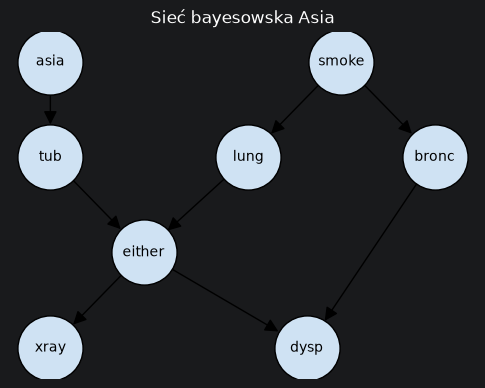

In [10]:
import matplotlib.pyplot as plt
import networkx as nx


pos = {
    "asia": (0, 3), "smoke": (2.5, 3),
    "tub": (0, 2), "lung": (1.7, 2), "bronc": (3.3, 2),
    "either": (0.8, 1),
    "xray": (0, 0), "dysp": (2.2, 0),
}

plt.figure(figsize=(6, 4.5))
nx.draw_networkx(asia_model, pos=pos, node_size=2200, node_color="#cfe2f3",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()


## 1.2 Weryfikacja CDP

In [11]:
for cpd in asia_model.get_cpds():
    print(cpd, end="\n\n")


+-----------+------+
| asia(yes) | 0.01 |
+-----------+------+
| asia(no)  | 0.99 |
+-----------+------+

+----------+-----------+----------+
| asia     | asia(yes) | asia(no) |
+----------+-----------+----------+
| tub(yes) | 0.05      | 0.01     |
+----------+-----------+----------+
| tub(no)  | 0.95      | 0.99     |
+----------+-----------+----------+

+------------+-----+
| smoke(yes) | 0.5 |
+------------+-----+
| smoke(no)  | 0.5 |
+------------+-----+

+-----------+------------+-----------+
| smoke     | smoke(yes) | smoke(no) |
+-----------+------------+-----------+
| lung(yes) | 0.1        | 0.01      |
+-----------+------------+-----------+
| lung(no)  | 0.9        | 0.99      |
+-----------+------------+-----------+

+------------+------------+-----------+
| smoke      | smoke(yes) | smoke(no) |
+------------+------------+-----------+
| bronc(yes) | 0.6        | 0.3       |
+------------+------------+-----------+
| bronc(no)  | 0.4        | 0.7       |
+------------+-------

## 1.3 Przykładowe Zapytania

In [12]:
from pgmpy.example_models import load_model
from pgmpy.inference import VariableElimination

loaded_asia_model = load_model("bnlearn/asia")
loaded_asia_infer = VariableElimination(loaded_asia_model)

asia_infer = VariableElimination(asia_model)

queries = [
{"variables": ["bronc"], "evidence": {"smoke":"no"}},
{"variables": ["bronc", "asia"], "evidence": {"smoke":"yes"}},
{"variables": ["bronc", "asia"], "evidence": {"smoke":"no"}},
]

for idx, q in enumerate(queries, start=1):
    print(f"# {idx} query")
    print("Loaded Model")
    print(loaded_asia_infer.query(variables=q["variables"], evidence=q["evidence"]))
    print("My Model")
    print(asia_infer.query(variables=q["variables"], evidence=q["evidence"]))
    print()
    print()

# 1 query
Loaded Model
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+
My Model
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+


# 2 query
Loaded Model
+------------+-----------+-------------------+
| bronc      | asia      |   phi(bronc,asia) |
+============+===========+===================+
| bronc(yes) | asia(yes) |            0.0060 |
+------------+-----------+-------------------+
| bronc(yes) | asia(no)  |            0.5940 |
+------------+-----------+-------------------+
| bronc(no)  | asia(yes) |            0.0040 |
+------------+-----------+-------------------+
| bronc(no)  | asia(no)  |            0.3960 |
+------------+-----------+-------------------+
My Mod

# 2. Rozszerzenie modelu

In [38]:
asia_model.add_edge('bronc', 'cough')
asia_model.add_edge('either', 'cough')


cdp_cough = TabularCPD(
    variable="cough",
    variable_card=2,
    # Columns: either=[yes, no] | Rows: xray=[yes, no]
    # [ (yes,yes), (yes,no), (no,yes), (no,no) ]
    values=[
        [0.95, 0.7, 0.9, 0.5],  # yes
        [0.05, 0.3, 0.1, 0.5]   # no
    ],
    evidence=["bronc", "either"],
    evidence_card=[2, 2],
    state_names={
        "cough": ["yes", "no"],
        "bronc": ["yes", "no"],
        "either": ["yes", "no"],
    }
)

asia_model.add_cpds(cdp_cough)

asia_model.check_model()

True

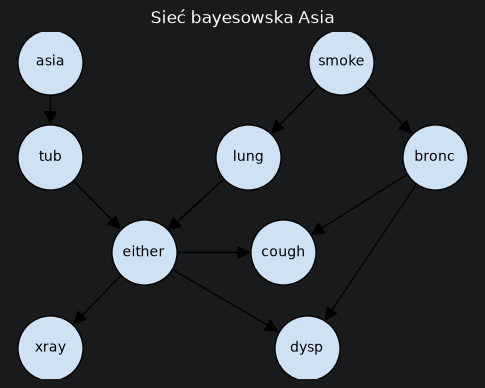

In [39]:
pos = {
    "asia": (0, 3), "smoke": (2.5, 3),
    "tub": (0, 2), "lung": (1.7, 2), "bronc": (3.3, 2),
    "either": (0.8, 1),
    "xray": (0, 0), "dysp": (2.2, 0), "cough":(2, 1)
}

plt.figure(figsize=(6, 4.5))
nx.draw_networkx(asia_model, pos=pos, node_size=2200, node_color="#cfe2f3",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()


## 2.1 Diagnoza Pacjenta
Dodaj do sieci nową zmienną, np. `cough` (kaszel), zależną od `bronc` i `either`, z samodzielnie zaproponowanymi CPD. Jak obserwacja kaszlu zmienia diagnozę dla pacjenta z rozdziału 4.2?

In [41]:
import pandas as pd


asia_infer = VariableElimination(asia_model)
diseases = ["tub", "lung", "bronc"]

def diagnose(evidence):
    # Zwraca P(choroba = yes | evidence) dla każdej choroby
    q = asia_infer.query(variables=diseases, evidence=evidence, joint=False)
    return {d: round(q[d].get_value(**{d: "yes"}), 4) for d in diseases}


scenarios = {
    "brak informacji": {},
    "duszność": {"dysp": "yes"},
    "duszność + pali": {"dysp": "yes", "smoke": "yes"},
    "duszność + pali + RTG nieprawidłowe": {"dysp": "yes", "smoke": "yes", "xray": "yes"},
    "duszność + pali + RTG nieprawidłowe + Azja": {"dysp": "yes", "smoke": "yes", "xray": "yes", "asia": "yes"},
}


scenarios_with_cough = {
    "kaszel": {"cough": "yes"},
    "kaszel + duszność": {"cough": "yes", "dysp": "yes"},
    "kaszel +duszność + pali": {"cough": "yes", "dysp": "yes", "smoke": "yes"},
    "kaszel +duszność + pali + RTG nieprawidłowe": {"cough": "yes", "dysp": "yes", "smoke": "yes", "xray": "yes"},
    "kaszel +duszność + pali + RTG nieprawidłowe + Azja": {"cough": "yes", "dysp": "yes", "smoke": "yes", "xray": "yes", "asia": "yes"},
}


diag = pd.DataFrame({name: diagnose(ev) for name, ev in scenarios.items()}).T
display(diag)

diag_c = pd.DataFrame({name: diagnose(ev) for name, ev in scenarios_with_cough.items()}).T
display(diag_c)

,tub,lung,bronc
brak informacji,0.0104,0.0550,0.4500
duszność,0.0188,0.1028,0.8340
duszność + pali,0.0154,0.1483,0.8802
duszność + pali + RTG nieprawidłowe,0.0753,0.7237,0.7137
duszność + pali + RTG nieprawidłowe + Azja,0.2896,0.5792,0.7009


,tub,lung,bronc
kaszel,0.0157,0.0837,0.5306
kaszel + duszność,0.0248,0.1360,0.8556
kaszel +duszność + pali,0.0199,0.1909,0.8868
kaszel +duszność + pali + RTG nieprawidłowe,0.0797,0.7662,0.7149
kaszel +duszność + pali + RTG nieprawidłowe + Azja,0.3025,0.6050,0.7041


# 3. Analiza Wrażliwości
Zbadaj, jak $P(\text{lung}=\text{yes} \mid \text{xray}=\text{yes}, \text{dysp}=\text{yes}, \text{smoke}=\text{yes})$ zależy od czułości RTG, tj. od $P(\text{xray}=\text{yes} \mid \text{either}=\text{yes})$ zmienianego w zakresie 0,5–1. Przedstaw wynik na wykresie.